In [12]:
import pandas as pd
from pathlib import Path

RESULTS_DIR = Path("../data")

files = {
    "funnel": "funnel_results.csv",
    "retention": "retention_results.csv",
    "revenue": "revenue_results.csv",
    "profit": "profit_results.csv",
}

results = {}

for name, filename in files.items():
    path = RESULTS_DIR / filename
    results[name] = pd.read_csv(path)

    print(f"\n{'=' * 15} {name} {'=' * 15}")
    print("行数、列数：", results[name].shape)
    print("字段：", results[name].columns.tolist())
    display(results[name])


=============== funnel ===============
行数、列数： (2, 10)
字段： ['experiment_group', 'total_users', 'exposed_users', 'clicked_users', 'cart_users', 'purchased_users', 'click_rate_pct', 'cart_conversion_pct', 'payment_conversion_pct', 'overall_conversion_pct']


,experiment_group,total_users,exposed_users,clicked_users,cart_users,purchased_users,click_rate_pct,cart_conversion_pct,payment_conversion_pct,overall_conversion_pct
0,A,13000,13000,5255,2698,1089,40.42,51.34,40.36,8.38
1,B,13000,13000,5614,2846,1147,43.18,50.69,40.30,8.82



=============== retention ===============
行数、列数： (2, 6)
字段： ['experiment_group', 'total_users', 'd1_active_users', 'd1_retention_pct', 'd7_active_users', 'd7_retention_pct']


,experiment_group,total_users,d1_active_users,d1_retention_pct,d7_active_users,d7_retention_pct
0,A,13000,3198,24.60,1572,12.09
1,B,13000,3307,25.44,1602,12.32



=============== revenue ===============
行数、列数： (2, 8)
字段： ['experiment_group', 'total_users', 'total_orders', 'purchasing_users', 'total_revenue', 'arpu', 'aov', 'revenue_per_purchasing_user']


,experiment_group,total_users,total_orders,purchasing_users,total_revenue,arpu,aov,revenue_per_purchasing_user
0,A,13000,1089,1089,67416.44,5.19,61.91,61.91
1,B,13000,1147,1147,71274.97,5.48,62.14,62.14



=============== profit ===============
行数、列数： (2, 9)
字段： ['experiment_group', 'total_users', 'total_orders', 'refunded_orders', 'total_revenue', 'total_contribution_profit', 'contribution_profit_per_user', 'refund_order_rate_pct', 'refund_amount_rate_pct']


,experiment_group,total_users,total_orders,refunded_orders,total_revenue,total_contribution_profit,contribution_profit_per_user,refund_order_rate_pct,refund_amount_rate_pct
0,A,13000,1089,54,67416.44,20389.70,1.57,4.96,4.76
1,B,13000,1147,64,71274.97,21390.69,1.65,5.58,4.99


In [13]:
# 检查每份结果是否都包含 A、B 两组
for name, df in results.items():
    print(f"\n{name}")
    print(df[["experiment_group", "total_users"]])

# 检查每份结果的总用户数是否一致
for name, df in results.items():
    print(
        f"{name}: "
        f"总用户数 = {df['total_users'].sum():,}"
    )

# 检查每组的用户数
print("\n漏斗结果：")
display(
    results["funnel"][
        ["experiment_group", "total_users",
         "exposed_users", "purchased_users",
         "overall_conversion_pct"]
    ]
)


funnel
  experiment_group  total_users
0                A        13000
1                B        13000

retention
  experiment_group  total_users
0                A        13000
1                B        13000

revenue
  experiment_group  total_users
0                A        13000
1                B        13000

profit
  experiment_group  total_users
0                A        13000
1                B        13000
funnel: 总用户数 = 26,000
retention: 总用户数 = 26,000
revenue: 总用户数 = 26,000
profit: 总用户数 = 26,000

漏斗结果：


,experiment_group,total_users,exposed_users,purchased_users,overall_conversion_pct
0,A,13000,13000,1089,8.38
1,B,13000,13000,1147,8.82


In [14]:
import numpy as np
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.proportion import confint_proportions_2indep

funnel = results["funnel"].copy()
funnel["experiment_group"] = (
    funnel["experiment_group"].astype(str).str.strip()
)

# 分别取出 A、B 组
a = funnel.loc[
    funnel["experiment_group"] == "A"
].iloc[0]

b = funnel.loc[
    funnel["experiment_group"] == "B"
].iloc[0]

# 转化人数与样本量
x_a = int(a["purchased_users"])
n_a = int(a["total_users"])

x_b = int(b["purchased_users"])
n_b = int(b["total_users"])

# 转化率
p_a = x_a / n_a
p_b = x_b / n_b

# 绝对提升、相对提升
absolute_lift = p_b - p_a
relative_lift = absolute_lift / p_a if p_a > 0 else np.nan

# 双侧 z 检验
count = np.array([x_b, x_a])
nobs = np.array([n_b, n_a])

z_stat, p_value = proportions_ztest(
    count=count,
    nobs=nobs,
    alternative="two-sided"
)

# B 组减 A 组的 95% 置信区间
ci_low, ci_high = confint_proportions_2indep(
    count1=x_b,
    nobs1=n_b,
    count2=x_a,
    nobs2=n_a,
    method="newcomb",
    alpha=0.05
)

print(f"A 组转化率：{p_a:.2%} ({x_a}/{n_a})")
print(f"B 组转化率：{p_b:.2%} ({x_b}/{n_b})")
print(f"绝对提升：{absolute_lift:.2%}（百分点）")
print(f"相对提升：{relative_lift:.2%}")
print(f"95% 置信区间：[{ci_low:.2%}, {ci_high:.2%}]")
print(f"z 统计量：{z_stat:.4f}")
print(f"p 值：{p_value:.6f}")

if p_value < 0.05:
    print("统计结论：在 5% 显著性水平下，两组转化率存在统计显著差异。")
else:
    print("统计结论：在 5% 显著性水平下，尚无充分证据认为两组转化率存在差异。")

A 组转化率：8.38% (1089/13000)
B 组转化率：8.82% (1147/13000)
绝对提升：0.45%（百分点）
相对提升：5.33%
95% 置信区间：[-0.24%, 1.13%]
z 统计量：1.2830
p 值：0.199500
统计结论：在 5% 显著性水平下，尚无充分证据认为两组转化率存在差异。


In [4]:
import numpy as np
import pandas as pd
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)
from statsmodels.stats.multitest import multipletests

# 读取漏斗汇总结果
funnel = results["funnel"].copy()
funnel["experiment_group"] = (
    funnel["experiment_group"].astype(str).str.strip()
)

a = funnel.loc[funnel["experiment_group"] == "A"].iloc[0]
b = funnel.loc[funnel["experiment_group"] == "B"].iloc[0]

# 指标名称、分子、分母
metrics = [
    ("点击率", "clicked_users", "total_users"),
    ("点击后加购率", "cart_users", "clicked_users"),
    ("加购后支付率", "purchased_users", "cart_users"),
    ("整体首单转化率", "purchased_users", "total_users"),
]

rows = []

for name, numerator, denominator in metrics:
    # A 组
    x_a = int(a[numerator])
    n_a = int(a[denominator])

    # B 组
    x_b = int(b[numerator])
    n_b = int(b[denominator])

    p_a = x_a / n_a
    p_b = x_b / n_b
    diff = p_b - p_a

    # 双侧两比例 z 检验
    z_stat, p_value = proportions_ztest(
        count=[x_b, x_a],
        nobs=[n_b, n_a],
        alternative="two-sided"
    )

    # B 组减 A 组的 95% 置信区间
    ci_low, ci_high = confint_proportions_2indep(
        count1=x_b,
        nobs1=n_b,
        count2=x_a,
        nobs2=n_a,
        method="newcomb",
        alpha=0.05
    )

    rows.append({
        "指标": name,
        "A组转化率(%)": p_a * 100,
        "B组转化率(%)": p_b * 100,
        "绝对差异(百分点)": diff * 100,
        "相对提升(%)": (
            diff / p_a * 100 if p_a > 0 else np.nan
        ),
        "95%CI下限(百分点)": ci_low * 100,
        "95%CI上限(百分点)": ci_high * 100,
        "z统计量": z_stat,
        "原始p值": p_value
    })

test_results = pd.DataFrame(rows)

# 对四项检验的 p 值进行 Holm 校正
test_results["Holm校正p值"] = multipletests(
    test_results["原始p值"],
    alpha=0.05,
    method="holm"
)[1]

test_results["校正后是否显著"] = (
    test_results["Holm校正p值"] < 0.05
)

display(
    test_results.round(4)
)


,指标,A组转化率(%),B组转化率(%),绝对差异(百分点),相对提升(%),95%CI下限(百分点),95%CI上限(百分点),z统计量,原始p值,Holm校正p值,校正后是否显著
0,点击率,40.4231,43.1846,2.7615,6.8316,1.5625,3.9594,4.5139,0.0000,0.0000,True
1,点击后加购率,51.3416,50.6947,-0.6469,-1.2600,-2.5264,1.2334,-0.6742,0.5002,1.0000,False
2,加购后支付率,40.3632,40.3022,-0.0611,-0.1513,-2.6437,2.5202,-0.0463,0.9631,1.0000,False
3,整体首单转化率,8.3769,8.8231,0.4462,5.3260,-0.2356,1.1282,1.2830,0.1995,0.5985,False


### 漏斗分析与统计检验结论

实验结果显示，增加个性化商品推荐模块后，B 组点击率从 40.42% 上升至 43.18%，提高 2.76 个百分点，且差异具有统计显著性，说明该模块能够有效吸引用户点击商品。

然而，B 组点击后加购率和加购后支付率均未表现出统计显著的变化。最终，B 组 7 日首单转化率为 8.82%，高于 A 组的 8.38%，但差异未达到 5% 的统计显著性水平（p = 0.1995）。

因此，本次实验支持“推荐模块提高了商品点击率”，但尚不足以证明其显著提高了最终首单转化率。后续应结合用户收入、贡献利润、退款率等指标评估其商业价值，并进一步探索点击增长未能转化为显著支付增长的原因。

## 业务结论与实验建议

### 1. 实验核心发现

本次实验旨在评估电商 App 新用户首页增加个性化商品推荐模块的效果。A 组使用原有首页，B 组使用增加推荐模块的首页，每组各有 13,000 名用户。实验以注册后 7×24 小时内完成首单的用户比例作为主指标，并结合漏斗、收入和贡献利润评估推荐模块的业务表现。

**（1）主指标：首单转化率有所提高，但未达到统计显著水平。**

A 组 7 日首单转化率为 8.38%（1,089/13,000），B 组为 8.82%（1,147/13,000），绝对提升约 0.45 个百分点，相对提升约 5.33%。两比例检验的 p 值为 0.1995，95% 置信区间约为 [-0.24, 1.13] 个百分点。因此，在 5% 显著性水平下，尚无充分证据证明个性化推荐模块提高了首单转化率。

**（2）漏斗分析：点击率显著提高，但后续转化没有明显改善。**

B 组点击率从 40.42% 上升至 43.18%，提高 2.76 个百分点；点击后加购率从 51.34% 降至 50.69%，加购后支付率则基本保持不变。点击率的统计检验显示差异显著，而后两个阶段的差异未达到统计显著水平。这表明推荐模块有效吸引了更多用户点击商品，但新增点击尚未转化为明确的最终购买提升。

**（3）收入与利润：B 组的观测值更高，但统计可靠性仍待验证。**

B 组总收入为 71,274.97，高于 A 组的 67,416.44，增长约 5.72%；总贡献利润从 20,389.70 上升至 21,390.69，增长约 4.91%。与此同时，B 组平均订单金额仅小幅提高，退款订单率从 4.96% 上升至 5.58%。这些结果显示 B 组在收入和贡献利润方面具有正向的观测差异，但当前分析尚未检验人均收入和人均贡献利润差异的统计显著性，也尚未扣除推荐模块的额外开发、运营和维护成本。

### 2. 业务建议

基于当前结果，建议暂不直接全面推广个性化推荐模块，而是将其视为一个具有潜力、但仍需验证最终商业价值的优化方案。

后续可优先从以下方面开展优化：

- **优化推荐质量：** 检查推荐商品与新用户需求的匹配程度，探索提高点击后的加购转化率。
- **排查转化阻碍：** 结合商品价格、商品详情、库存和支付流程等信息，分析点击与加购、支付之间的流失原因。
- **持续监控业务护栏：** 关注退款率、页面加载时间和用户体验，避免通过增加点击带来额外成本或负面影响。
- **开展后续实验：** 在明确优化方向后，进行新一轮 A/B 测试，继续以 7 日首单转化率为主指标，并结合收入、贡献利润和系统成本判断是否值得推广。

### 3. 最终结论

本次模拟实验展示了从实验设计、SQL 指标计算到 Python 统计检验和业务解读的完整分析流程。结果表明，个性化推荐模块显著提高了商品点击率，并伴随总收入和总贡献利润的正向变化，但尚未提供足够的统计证据证明其提高了最终首单转化率。因此，合理的业务决策不是简单地认定实验成功或失败，而是进一步优化点击后的转化效率，并在综合考虑收益、成本和用户体验后决定是否推广。

In [15]:

# 整理 A/B 两组收入与贡献利润数据
revenue = results["revenue"].copy()
profit = results["profit"].copy()

revenue["experiment_group"] = (
    revenue["experiment_group"].astype(str).str.strip()
)
profit["experiment_group"] = (
    profit["experiment_group"].astype(str).str.strip()
)

rev_a = revenue.loc[
    revenue["experiment_group"] == "A"
].iloc[0]
rev_b = revenue.loc[
    revenue["experiment_group"] == "B"
].iloc[0]

prof_a = profit.loc[
    profit["experiment_group"] == "A"
].iloc[0]
prof_b = profit.loc[
    profit["experiment_group"] == "B"
].iloc[0]

# 计算收入增幅
revenue_diff = rev_b["total_revenue"] - rev_a["total_revenue"]
revenue_growth = revenue_diff / rev_a["total_revenue"]

arpu_diff = rev_b["arpu"] - rev_a["arpu"]
aov_growth = (rev_b["aov"] - rev_a["aov"]) / rev_a["aov"]

# 计算贡献利润增幅
profit_diff = (
    prof_b["total_contribution_profit"]
    - prof_a["total_contribution_profit"]
)
profit_growth = (
    profit_diff / prof_a["total_contribution_profit"]
)

profit_per_user_diff = (
    prof_b["contribution_profit_per_user"]
    - prof_a["contribution_profit_per_user"]
)

# 输出结果
summary = pd.DataFrame({
    "指标": [
        "总收入",
        "人均收入（ARPU）",
        "平均订单金额（AOV）",
        "总贡献利润",
        "人均贡献利润"
    ],
    "A组": [
        rev_a["total_revenue"],
        rev_a["arpu"],
        rev_a["aov"],
        prof_a["total_contribution_profit"],
        prof_a["contribution_profit_per_user"]
    ],
    "B组": [
        rev_b["total_revenue"],
        rev_b["arpu"],
        rev_b["aov"],
        prof_b["total_contribution_profit"],
        prof_b["contribution_profit_per_user"]
    ]
})

display(summary.round(2))

print(f"总收入增加：{revenue_diff:,.2f}（增长 {revenue_growth:.2%}）")
print(f"ARPU 增加：{arpu_diff:.2f}")
print(f"AOV 增长：{aov_growth:.2%}")
print(
    f"总贡献利润增加：{profit_diff:,.2f}"
    f"（增长 {profit_growth:.2%}）"
)
print(f"人均贡献利润增加：{profit_per_user_diff:.4f}")


,指标,A组,B组
0,总收入,67416.44,71274.97
1,人均收入（ARPU）,5.19,5.48
2,平均订单金额（AOV）,61.91,62.14
3,总贡献利润,20389.70,21390.69
4,人均贡献利润,1.57,1.65


总收入增加：3,858.53（增长 5.72%）
ARPU 增加：0.29
AOV 增长：0.37%
总贡献利润增加：1,000.99（增长 4.91%）
人均贡献利润增加：0.0800


In [16]:
# ROI 情景分析：以下成本为人为设定的模拟假设
incremental_cost = 500.00

# 假设两组贡献利润差异可作为增量贡献利润的情景估计
incremental_contribution_profit = profit_diff

net_incremental_profit = (
    incremental_contribution_profit - incremental_cost
)

roi = (
    net_incremental_profit / incremental_cost
    if incremental_cost > 0
    else np.nan
)

roi_summary = pd.DataFrame({
    "指标": [
        "A组总贡献利润",
        "B组总贡献利润",
        "观测到的贡献利润差额",
        "假设的推荐模块额外成本",
        "扣除额外成本后的增量利润",
        "ROI"
    ],
    "数值": [
        prof_a["total_contribution_profit"],
        prof_b["total_contribution_profit"],
        incremental_contribution_profit,
        incremental_cost,
        net_incremental_profit,
        roi
    ]
})

display(roi_summary.round(4))

print(f"模拟额外成本：{incremental_cost:,.2f}")
print(f"扣除额外成本后的增量利润：{net_incremental_profit:,.2f}")
print(f"情景 ROI：{roi:.2%}" if pd.notna(roi) else "成本为零，无法计算 ROI")


,指标,数值
0,A组总贡献利润,20389.700
1,B组总贡献利润,21390.690
2,观测到的贡献利润差额,1000.990
3,假设的推荐模块额外成本,500.000
4,扣除额外成本后的增量利润,500.990
5,ROI,1.002


模拟额外成本：500.00
扣除额外成本后的增量利润：500.99
情景 ROI：100.20%


## 收入、贡献利润与 ROI 情景分析

### 1. 收入与贡献利润表现

B 组总收入为 71,274.97，高于 A 组的 67,416.44，观测增幅约为 5.72%。B 组总贡献利润为 21,390.69，高于 A 组的 20,389.70，观测增幅约为 4.91%。这表明 B 组在收入和贡献利润方面均呈现正向差异。

### 2. ROI 情景分析

为演示推荐模块的成本收益评估，假设该模块在本次实验期间产生 500 个货币单位的额外成本。基于两组观测到的贡献利润差额 1,000.99，扣除该成本后，情景增量利润为 500.99，对应 ROI 约为 100.20%。

该结果仅用于展示成本收益分析的计算方法。额外成本属于人为设定的模拟参数，并非真实业务成本。

### 3. 业务解释与决策限制

本次实验中，B 组点击率显著提高，但首单转化率差异未达到统计显著水平。虽然 B 组收入和贡献利润的观测值更高，但目前尚未检验人均收入和人均贡献利润差异的统计显著性。因此，不能将观测到的贡献利润差额直接视为已经得到统计确认的增量收益。

此外，当前 ROI 情景分析依赖假设成本和观测到的贡献利润差额，未充分考虑成本估计误差、长期维护成本及长期用户价值。该结果不能单独作为全面推广推荐模块的充分依据。

综合来看，个性化推荐模块表现出提高商品点击率的潜力，并伴随收入和贡献利润的正向变化。后续应进一步优化点击后的转化效率，并结合更可靠的成本数据和实验结果评估其商业价值。

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# 统一图表风格
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.unicode_minus"] = False

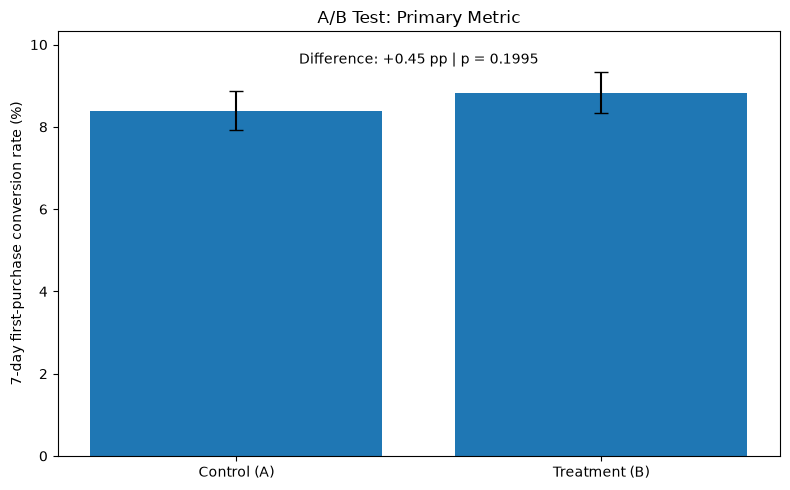

In [8]:
# 主指标数据，单位：百分比
groups = ["Control (A)", "Treatment (B)"]
rates = [8.38, 8.82]

# 每组比例的 Wilson 95% 置信区间
from statsmodels.stats.proportion import proportion_confint

counts = [1089, 1147]
nobs = [13000, 13000]

ci = [
    proportion_confint(count, n, alpha=0.05, method="wilson")
    for count, n in zip(counts, nobs)
]

lower = [x[0] * 100 for x in ci]
upper = [x[1] * 100 for x in ci]
yerr = [
    [rate - lo for rate, lo in zip(rates, lower)],
    [hi - rate for rate, hi in zip(rates, upper)],
]

fig, ax = plt.subplots()
ax.bar(groups, rates, yerr=yerr, capsize=5)
ax.set_ylabel("7-day first-purchase conversion rate (%)")
ax.set_title("A/B Test: Primary Metric")
ax.text(
    0.5, 0.95,
    "Difference: +0.45 pp | p = 0.1995",
    transform=ax.transAxes,
    ha="center",
    va="top"
)
ax.set_ylim(0, max(upper) + 1)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_ab_test_result.png", dpi=200, bbox_inches="tight")
plt.show()

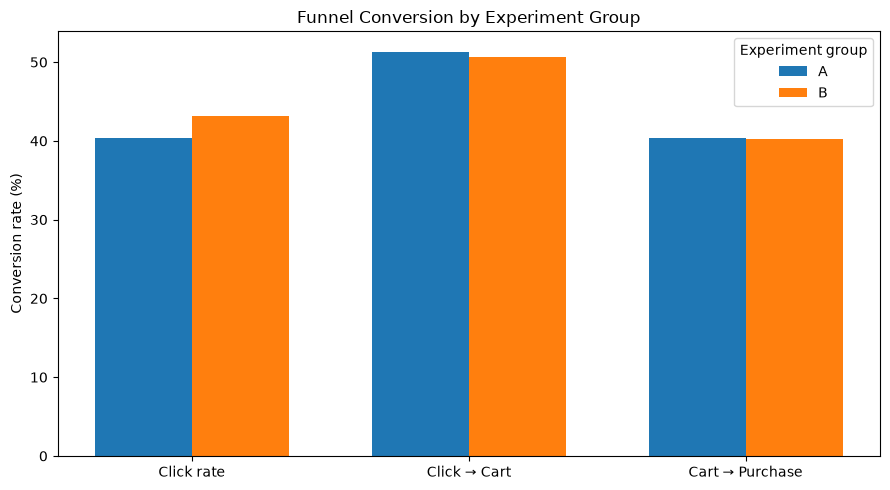

In [17]:
funnel = results["funnel"].copy()

# 设置展示标签
funnel["group_label"] = funnel["experiment_group"].astype(str)

stages = [
    ("click_rate_pct", "Click rate"),
    ("cart_conversion_pct", "Click → Cart"),
    ("payment_conversion_pct", "Cart → Purchase"),
]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(stages))
width = 0.35

for i, (_, row) in enumerate(funnel.iterrows()):
    values = [row[col] for col, _ in stages]
    offset = (i - (len(funnel) - 1) / 2) * width
    ax.bar(x + offset, values, width, label=row["group_label"])

ax.set_xticks(x)
ax.set_xticklabels([label for _, label in stages])
ax.set_ylabel("Conversion rate (%)")
ax.set_title("Funnel Conversion by Experiment Group")
ax.legend(title="Experiment group")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_funnel_analysis.png", dpi=200, bbox_inches="tight")
plt.show()

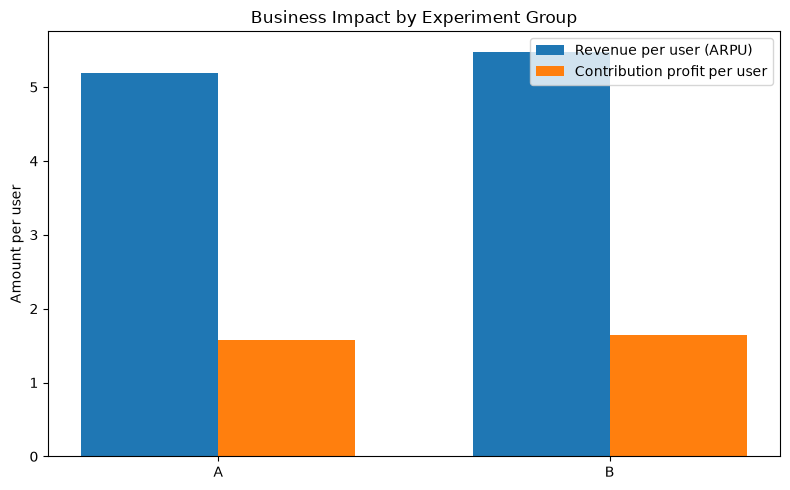

In [10]:
revenue = results["revenue"].copy()
profit = results["profit"].copy()

business = revenue[
    ["experiment_group", "arpu"]
].merge(
    profit[["experiment_group", "contribution_profit_per_user"]],
    on="experiment_group",
    how="inner"
)

x = np.arange(len(business))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    x - width / 2,
    business["arpu"],
    width,
    label="Revenue per user (ARPU)"
)
ax.bar(
    x + width / 2,
    business["contribution_profit_per_user"],
    width,
    label="Contribution profit per user"
)

ax.set_xticks(x)
ax.set_xticklabels(business["experiment_group"].astype(str))
ax.set_ylabel("Amount per user")
ax.set_title("Business Impact by Experiment Group")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_business_impact.png", dpi=200, bbox_inches="tight")
plt.show()

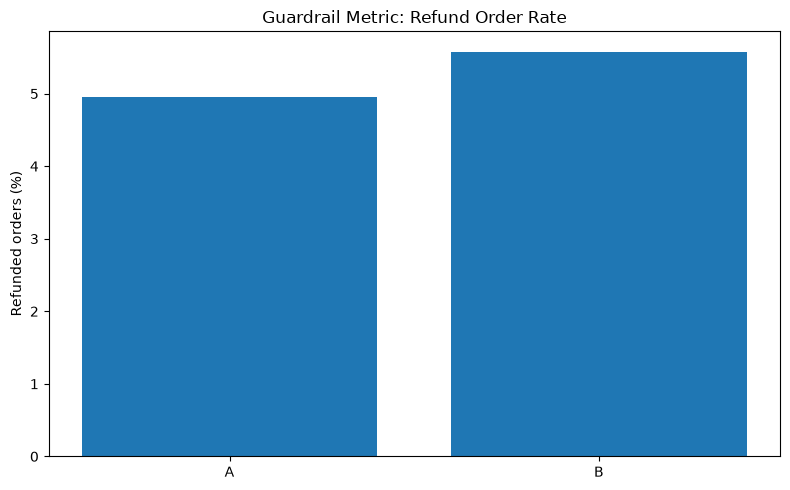

In [11]:
profit = results["profit"].copy()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    profit["experiment_group"].astype(str),
    profit["refund_order_rate_pct"]
)
ax.set_ylabel("Refunded orders (%)")
ax.set_title("Guardrail Metric: Refund Order Rate")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_guardrail_metrics.png", dpi=200, bbox_inches="tight")
plt.show()